# Target aiming and vision-precision analysis

本 Notebook 围绕四个工程问题展开：

1. 绿灯与装甲板的 yaw 差值能否用一个常量补偿；
2. 目标随滑轨移动后的瞄准结果；
3. 固定目标和弹道时 yaw 误差造成的板面位移；
4. 视觉角度精度与双目距离精度预算。

所有长度使用 m，角度统一使用 rad；图中仅将局部长度转换为 mm。装甲板表面坐标采用 u = local y、v = local z，local +x 为表面法向。

> 几何量直接读取 dart_description。修改 URDF 后应重新运行全部单元。
本 Notebook 第 1～3 节分析对方基地的完整滑轨行程；前哨站仅在初始化检查中核验目标接口。装甲板边界沿用当前模型的 100×100 mm 矩形假设，不代表已核验的实际有效区域。分析不依赖运行中的 ROS 节点，也不读取实时 joint_states。


In [2]:
from pathlib import Path
import sys
import yaml

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib_inline.backend_inline import set_matplotlib_formats


def find_repo_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        package = candidate / 'third_party/dart_description/target_geometry/__init__.py'
        if package.is_file():
            return candidate
    raise FileNotFoundError('Cannot locate the dart_vision repository root')


REPO_ROOT = find_repo_root()
DESCRIPTION_PYTHON = REPO_ROOT / 'third_party/dart_description'
if str(DESCRIPTION_PYTHON) not in sys.path:
    sys.path.insert(0, str(DESCRIPTION_PYTHON))

from target_geometry import Geometry

TEAM = 'red'  # red / blue；始终加载完整场景，选择对方目标
SCENE_URDF = DESCRIPTION_PYTHON / 'urdf/dart_system.urdf.xacro'
geometry = Geometry(path=SCENE_URDF, team=TEAM)
geometry.path

# Check both target families and the green-to-armor transform before analysis.
checks = []
for target, green_link, armor_link in [
    ('base', 'green_light_link', 'armor_link'),
    ('outpost', 'outpost_green_light_link', 'outpost_armor_link'),
]:
    relative = geometry.pose(armor_link, reference=green_link)
    checks.append({'target': target, 'team': TEAM,
                   'armor_from_green_x_mm': relative[0, 3] * 1000,
                   'armor_from_green_y_mm': relative[1, 3] * 1000,
                   'armor_from_green_z_mm': relative[2, 3] * 1000,
                   'center_separation_mm': np.linalg.norm(relative[:3, 3]) * 1000})
    assert np.isfinite(geometry.target_position(target)).all()
display(pd.DataFrame(checks))
print('Scene:', geometry.path)
print('Slide limits [m]:', geometry.slide_limits)
print('Yaw limits [rad]:', geometry.joint_limits('launcher_yaw_joint'))


,target,team,armor_from_green_x_mm,armor_from_green_y_mm,armor_from_green_z_mm,center_separation_mm
0,base,red,-68.315599,-0.004411,99.705715,120.864597
1,outpost,red,-68.315599,-0.004411,99.705715,120.864597


Scene: /home/zfx/RM_Vision/dart_vision/third_party/dart_description/urdf/dart_system.urdf.xacro
Slide limits [m]: (-0.28, 0.28)
Yaw limits [rad]: (-0.3490658503988659, 0.0)


In [3]:
set_matplotlib_formats('retina')
plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams.update({
    'figure.dpi': 140,
    'savefig.dpi': 320,
    'font.size': 10.5,
    'axes.titlesize': 12,
    'axes.labelsize': 10.5,
    'axes.titleweight': 'semibold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.28,
    'grid.linewidth': 0.7,
    'legend.frameon': False,
    'lines.linewidth': 2.0,
})

COLORS = {
    'green': '#2a9d8f',
    'armor': '#e76f51',
    'yaw': '#457b9d',
    'u': '#6a4c93',
    'v': '#f4a261',
    'offset': '#d62828',
}
SAVE_FIGURES = False
FIGURE_DIR = REPO_ROOT / 'analysis/tmp/target_impact_analysis' / TEAM


def finish_figure(fig, name):
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        figure_path = FIGURE_DIR / f'{name}.png'
        fig.savefig(figure_path, dpi=320, bbox_inches='tight')
        print(f'Saved {figure_path}')
    plt.show()


## 1. Can green-to-armor yaw use a constant offset?

对完整滑轨行程分别计算绿灯和装甲板中心的水平 bearing。用全行程 yaw 差值的均值作为候选常量，再检查残差及其在目标距离处对应的横向误差。是否可用常量由允许的水平横向误差预算决定，而不是只看曲线是否接近水平。

In [4]:
SLIDE_SAMPLES = 561
slides = np.linspace(*geometry.slide_limits, SLIDE_SAMPLES)

geometry_rows = []
for slide in slides:
    slide = float(slide)
    green = geometry.green_position(slide)
    armor = geometry.armor_position(slide)
    geometry_rows.append({
        'slide_m': slide,
        'green_x_m': green[0],
        'green_y_m': green[1],
        'green_distance_m': geometry.horizontal_distance(slide, link='green_light_link'),
        'green_bearing_rad': geometry.target_yaw(slide, link='green_light_link'),
        'armor_x_m': armor[0],
        'armor_y_m': armor[1],
        'armor_distance_m': geometry.horizontal_distance(slide),
        'armor_bearing_rad': geometry.target_yaw(slide),
    })

geometry_results = pd.DataFrame(geometry_rows)
geometry_results['distance_delta_m'] = (
    geometry_results['armor_distance_m'] - geometry_results['green_distance_m']
)
geometry_results['bearing_delta_rad'] = (
    geometry_results['armor_bearing_rad'] - geometry_results['green_bearing_rad']
)
CONSTANT_YAW_LATERAL_ERROR_BUDGET_M = 0.005
constant_yaw_offset_rad = geometry_results['bearing_delta_rad'].mean()
geometry_results['constant_yaw_residual_rad'] = (
    geometry_results['bearing_delta_rad'] - constant_yaw_offset_rad
)
geometry_results['constant_yaw_lateral_error_m'] = (
    geometry_results['armor_distance_m'] * geometry_results['constant_yaw_residual_rad']
)
display(geometry_results.iloc[[0, len(geometry_results) // 2, -1]].round(6))


,slide_m,green_x_m,green_y_m,green_distance_m,green_bearing_rad,armor_x_m,armor_y_m,armor_distance_m,armor_bearing_rad,distance_delta_m,bearing_delta_rad,constant_yaw_residual_rad,constant_yaw_lateral_error_m
0,-0.28,24.792278,-6.420475,25.610145,-0.253404,24.883382,-6.422550,25.698868,-0.252593,0.088723,0.000811,-0.000034,-0.000872
280,0.00,24.792278,-6.700379,25.681747,-0.263955,24.883382,-6.702454,25.770246,-0.263110,0.088499,0.000845,0.000000,0.000003
560,0.28,24.792278,-6.980283,25.756191,-0.274446,24.883382,-6.982358,25.844458,-0.273568,0.088267,0.000878,0.000034,0.000867


findfont: Failed to find font weight semibold for Liberation Sans, now using 700.


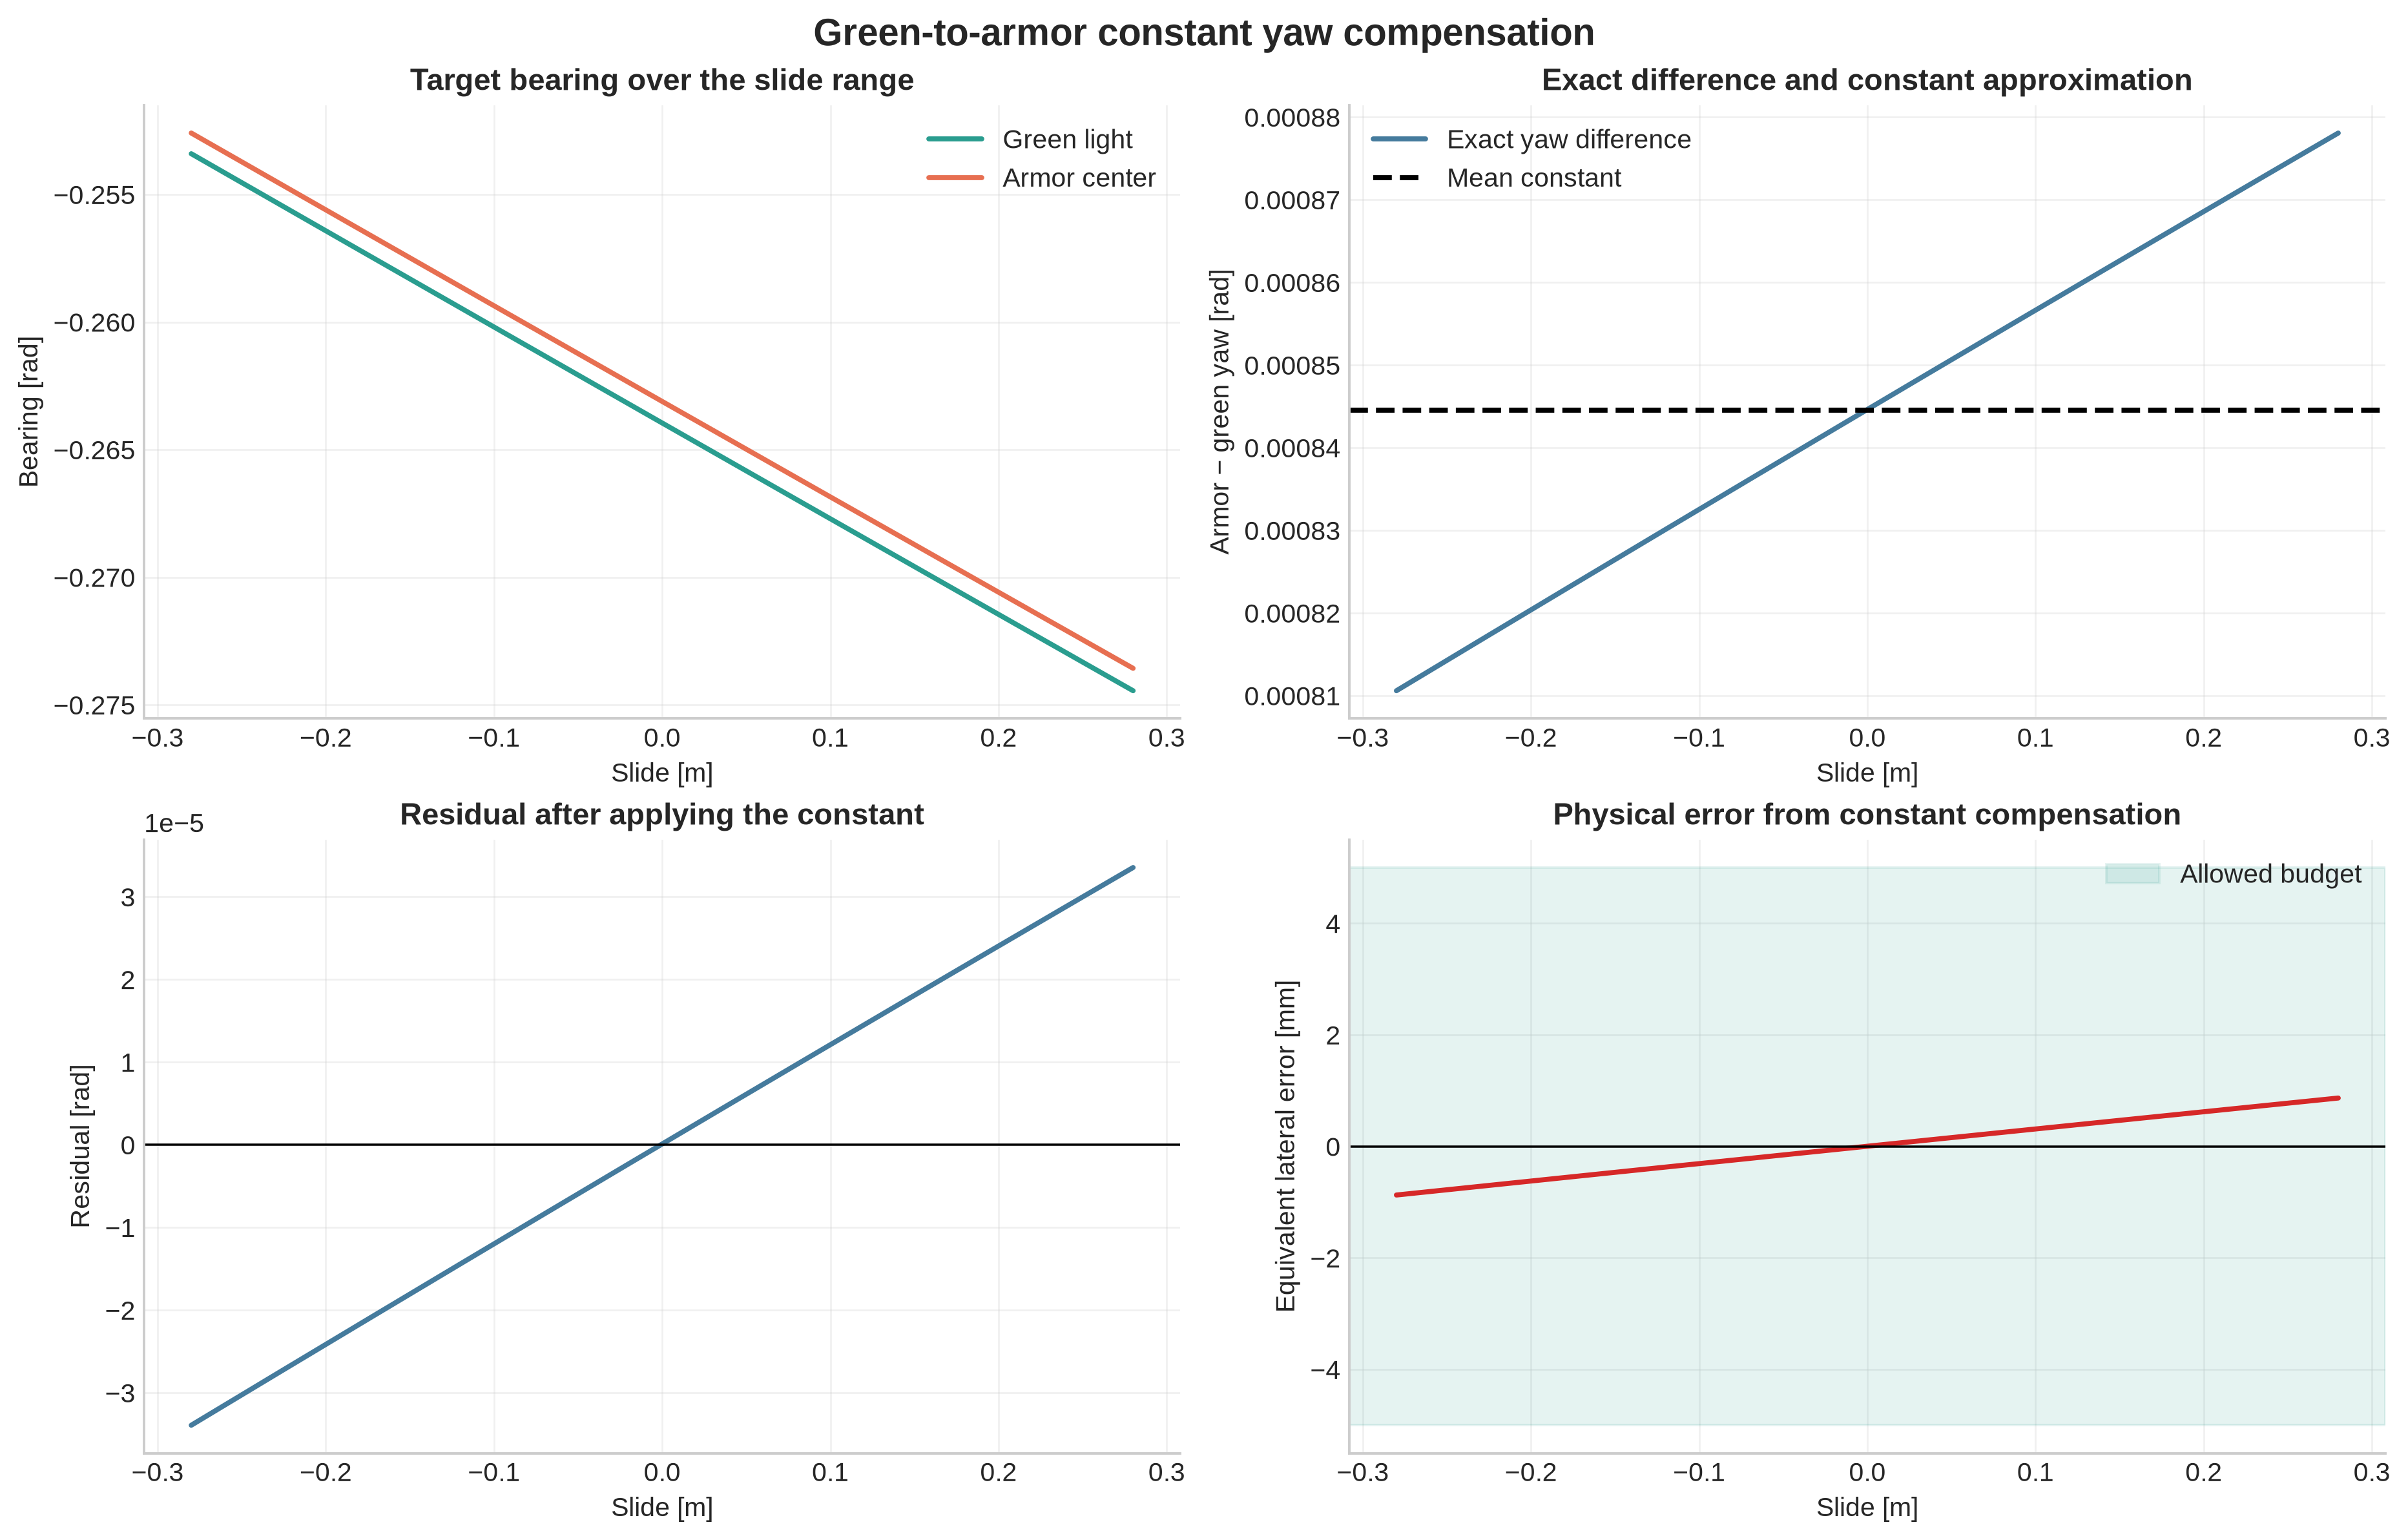

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13.2, 8.4), constrained_layout=True)

axes[0, 0].plot(slides, geometry_results['green_bearing_rad'], color=COLORS['green'], label='Green light')
axes[0, 0].plot(slides, geometry_results['armor_bearing_rad'], color=COLORS['armor'], label='Armor center')
axes[0, 0].set(xlabel='Slide [m]', ylabel='Bearing [rad]', title='Target bearing over the slide range')
axes[0, 0].legend()

axes[0, 1].plot(slides, geometry_results['bearing_delta_rad'], color=COLORS['yaw'], label='Exact yaw difference')
axes[0, 1].axhline(constant_yaw_offset_rad, color='black', linestyle='--', label='Mean constant')
axes[0, 1].set(xlabel='Slide [m]', ylabel='Armor − green yaw [rad]', title='Exact difference and constant approximation')
axes[0, 1].legend()

axes[1, 0].plot(slides, geometry_results['constant_yaw_residual_rad'], color=COLORS['yaw'])
axes[1, 0].axhline(0.0, color='black', linewidth=0.9)
axes[1, 0].set(xlabel='Slide [m]', ylabel='Residual [rad]', title='Residual after applying the constant')

surface_error_mm = geometry_results['constant_yaw_lateral_error_m'] * 1e3
budget_mm = CONSTANT_YAW_LATERAL_ERROR_BUDGET_M * 1e3
axes[1, 1].plot(slides, surface_error_mm, color=COLORS['offset'])
axes[1, 1].axhspan(-budget_mm, budget_mm, color=COLORS['green'], alpha=0.12, label='Allowed budget')
axes[1, 1].axhline(0.0, color='black', linewidth=0.9)
axes[1, 1].set(xlabel='Slide [m]', ylabel='Equivalent lateral error [mm]', title='Physical error from constant compensation')
axes[1, 1].legend()

fig.suptitle('Green-to-armor constant yaw compensation', fontsize=15, fontweight='bold')
finish_figure(fig, 'green_to_armor_yaw_offset')


In [6]:
max_constant_lateral_error_m = geometry_results['constant_yaw_lateral_error_m'].abs().max()
constant_yaw_is_acceptable = bool(max_constant_lateral_error_m <= CONSTANT_YAW_LATERAL_ERROR_BUDGET_M)
constant_yaw_summary = pd.Series({
    'constant_yaw_offset_rad': constant_yaw_offset_rad,
    'exact_delta_min_rad': geometry_results['bearing_delta_rad'].min(),
    'exact_delta_max_rad': geometry_results['bearing_delta_rad'].max(),
    'exact_delta_peak_to_peak_rad': np.ptp(geometry_results['bearing_delta_rad']),
    'residual_rms_rad': np.sqrt(np.mean(geometry_results['constant_yaw_residual_rad'] ** 2)),
    'maximum_abs_residual_rad': geometry_results['constant_yaw_residual_rad'].abs().max(),
    'maximum_equivalent_lateral_error_mm': max_constant_lateral_error_m * 1e3,
    'lateral_error_budget_mm': CONSTANT_YAW_LATERAL_ERROR_BUDGET_M * 1e3,
    'constant_is_acceptable': constant_yaw_is_acceptable,
})
display(constant_yaw_summary)


constant_yaw_offset_rad                0.000845
exact_delta_min_rad                    0.000811
exact_delta_max_rad                    0.000878
exact_delta_peak_to_peak_rad           0.000067
residual_rms_rad                        0.00002
maximum_abs_residual_rad               0.000034
maximum_equivalent_lateral_error_mm    0.872068
lateral_error_budget_mm                     5.0
constant_is_acceptable                     True
dtype: object

## 2. Aiming result as the target moves with the slide

geometric_yaw(slide) 令发射方向的水平中心线穿过随滑轨移动的装甲板中心。与直接使用 atan2 相比，这个求根形式在 URDF 增加离轨点横向偏置后仍然成立。

基准条件取滑轨零位：同一条二次竖直轨迹恰好穿过装甲板上表面中心。之后只改变 yaw，不改变发射仰角或轨迹曲率。

In [7]:
YAW_JOINT = 'launcher_yaw_joint'


def horizontal_launch_basis(yaw):
    direction = geometry.launch_direction(yaw)
    forward = direction.copy()
    forward[2] = 0.0
    forward /= np.linalg.norm(forward)
    left = np.array([-forward[1], forward[0], 0.0])
    return forward, left


def centerline_error(yaw, slide):
    release = geometry.release_position(yaw)
    target = geometry.armor_position(slide)
    _, left = horizontal_launch_basis(yaw)
    return float(np.dot(target - release, left))


def geometric_yaw(slide):
    lower, upper = geometry.joint_limits(YAW_JOINT)
    grid = np.linspace(lower, upper, 257)
    errors = np.array([centerline_error(yaw, slide) for yaw in grid])
    exact = np.flatnonzero(np.isclose(errors, 0.0, atol=1e-12))
    if exact.size:
        return float(grid[exact[0]])
    brackets = np.flatnonzero(errors[:-1] * errors[1:] < 0.0)
    if not brackets.size:
        raise ValueError(f'No centerline yaw solution for slide={slide}')
    expected = geometry.target_yaw(slide)
    index = min(brackets, key=lambda i: abs((grid[i] + grid[i + 1]) / 2 - expected))
    lo, hi = float(grid[index]), float(grid[index + 1])
    f_lo = centerline_error(lo, slide)
    for _ in range(60):
        mid = (lo + hi) / 2
        f_mid = centerline_error(mid, slide)
        if f_lo * f_mid <= 0.0:
            hi = mid
        else:
            lo, f_lo = mid, f_mid
    return (lo + hi) / 2


In [8]:
q0 = geometric_yaw(0.0)
release0 = geometry.release_position(q0)
target0 = geometry.armor_position(0.0)
forward0, _ = horizontal_launch_basis(q0)
range0 = float(np.dot(target0 - release0, forward0))
direction0 = geometry.launch_direction(q0)
launch_angle = np.arctan2(direction0[2], np.linalg.norm(direction0[:2]))

baseline = pd.Series({
    'baseline_yaw_rad': q0,
    'release_x_m': release0[0],
    'release_y_m': release0[1],
    'release_z_m': release0[2],
    'launch_angle_rad': launch_angle,
    'baseline_horizontal_range_m': range0,
    'baseline_cross_track_um': centerline_error(q0, 0.0) * 1e6,
})
display(baseline.round(6))


baseline_yaw_rad               -0.263110
release_x_m                     0.193117
release_y_m                    -0.052017
release_z_m                     0.691000
launch_angle_rad                0.558505
baseline_horizontal_range_m    25.570246
baseline_cross_track_um         0.000000
dtype: float64

### 2.1 Baseline trajectory and surface intersection

竖直轨迹采用 z(r) = z0 + r tan(alpha) + a r²。曲率 a 由零位命中装甲板中心的条件反算，因此这里研究的是几何敏感性，而不是完整弹道预测。模型不包含初速、飞行时间、空气阻力或发射机构动态误差。
这里 z/r 定义在 dart_base_link 坐标系中；场地含横坡，因此局部 z 不等同于重力竖直方向。这是一条人为构造的局部二次曲线，不应解释为重力弹道。交点选择靠近目标中心距离的正实根，未检查沿途遮挡。


In [9]:
trajectory_curvature = (
    target0[2] - release0[2] - range0 * np.tan(launch_angle)
) / range0**2


def trajectory_point(horizontal_range, yaw):
    release = geometry.release_position(yaw)
    forward, _ = horizontal_launch_basis(yaw)
    vertical = horizontal_range * np.tan(launch_angle) + trajectory_curvature * horizontal_range**2
    return release + forward * horizontal_range + np.array([0.0, 0.0, vertical])


def intersect_armor_surface(slide, yaw):
    surface = geometry.armor_surface(slide)
    release = geometry.release_position(yaw)
    forward, _ = horizontal_launch_basis(yaw)
    normal_z = surface.normal[2]
    coefficients = np.array([
        normal_z * trajectory_curvature,
        np.dot(surface.normal, forward) + normal_z * np.tan(launch_angle),
        np.dot(surface.normal, release - surface.center),
    ])
    coefficients = np.trim_zeros(coefficients, trim='f')
    roots = np.roots(coefficients)
    candidates = np.array([
        root.real for root in roots if abs(root.imag) < 1e-9 and root.real >= 0
    ])
    if not candidates.size:
        raise ValueError(f'Trajectory does not intersect the armor plane for slide={slide}')
    expected_range = np.dot(surface.center - release, forward)
    horizontal_range = float(candidates[np.argmin(abs(candidates - expected_range))])
    hit = trajectory_point(horizontal_range, yaw)
    local = surface.coordinates(hit)
    return horizontal_range, hit, local, surface.contains(hit, normal_tolerance=1e-7)


baseline_range, baseline_hit, baseline_local, baseline_inside = intersect_armor_surface(0.0, q0)
display(pd.Series({
    'trajectory_curvature_1_per_m': trajectory_curvature,
    'baseline_surface_u_um': baseline_local[0] * 1e6,
    'baseline_surface_v_um': baseline_local[1] * 1e6,
    'baseline_normal_error_um': baseline_local[2] * 1e6,
    'baseline_inside_armor': baseline_inside,
}).round(6))


trajectory_curvature_1_per_m   -0.023788
baseline_surface_u_um               -0.0
baseline_surface_v_um                0.0
baseline_normal_error_um             0.0
baseline_inside_armor                  1
dtype: object

### 2.2 Full slide sweep

对每个滑轨位置求几何 yaw，再计算固定基准轨迹与有限装甲板表面的交点。结果表同时保留数值残差，便于识别求根或坐标变换错误。

In [10]:
rows = []
for slide in slides:
    slide = float(slide)
    yaw = geometric_yaw(slide)
    horizontal_range, hit, local, inside = intersect_armor_surface(slide, yaw)
    target = geometry.armor_position(slide)
    release = geometry.release_position(yaw)
    forward, _ = horizontal_launch_basis(yaw)
    rows.append({
        'slide_m': slide,
        'yaw_rad': yaw,
        'yaw_delta_rad': yaw - q0,
        'centerline_error_m': centerline_error(yaw, slide),
        'target_horizontal_distance_m': geometry.horizontal_distance(slide),
        'centerline_target_range_m': float(np.dot(target - release, forward)),
        'trajectory_horizontal_range_m': horizontal_range,
        'hit_x_m': hit[0],
        'hit_y_m': hit[1],
        'hit_z_m': hit[2],
        'surface_u_m': local[0],
        'surface_v_m': local[1],
        'surface_normal_error_m': local[2],
        'surface_offset_m': np.hypot(local[0], local[1]),
        'inside_armor': inside,
    })

results = pd.DataFrame(rows)
display(results.iloc[[0, len(results) // 4, len(results) // 2, 3 * len(results) // 4, -1]].round(7))


,slide_m,yaw_rad,yaw_delta_rad,centerline_error_m,target_horizontal_distance_m,centerline_target_range_m,trajectory_horizontal_range_m,hit_x_m,hit_y_m,hit_z_m,surface_u_m,surface_v_m,surface_normal_error_m,surface_offset_m,inside_armor
0,-0.28,-0.252593,0.010517,0.0,25.698868,25.498868,25.530873,24.914371,-6.430548,1.139146,0.007579,0.034937,0.0,0.035749,True
140,-0.14,-0.257859,0.005251,0.0,25.734201,25.534201,25.550418,24.899062,-6.566637,1.127610,0.003923,0.017677,-0.0,0.018107,True
280,0.00,-0.263110,0.000000,0.0,25.770246,25.570246,25.570246,24.883382,-6.702454,1.115888,-0.000000,0.000000,0.0,0.000000,True
420,0.14,-0.268347,-0.005236,0.0,25.806999,25.606999,25.590355,24.867333,-6.837993,1.103982,-0.004196,-0.018093,-0.0,0.018573,True
560,0.28,-0.273568,-0.010458,0.0,25.844458,25.644458,25.610740,24.850918,-6.973248,1.091892,-0.008670,-0.036600,0.0,0.037613,True


In [11]:
zero_index = int(np.abs(results['slide_m']).argmin())
yaw_gradient = np.gradient(results['yaw_delta_rad'], results['slide_m'])
u_gradient = np.gradient(results['surface_u_m'] * 1e3, results['slide_m'])
v_gradient = np.gradient(results['surface_v_m'] * 1e3, results['slide_m'])
worst_index = int(results['surface_offset_m'].idxmax())
worst = results.loc[worst_index]

diagnostics = pd.Series({
    'yaw_span_rad': np.ptp(results['yaw_rad']),
    'local_yaw_sensitivity_rad_per_m': yaw_gradient[zero_index],
    'local_surface_u_sensitivity_mm_per_m': u_gradient[zero_index],
    'local_surface_v_sensitivity_mm_per_m': v_gradient[zero_index],
    'maximum_impact_offset_mm': worst['surface_offset_m'] * 1e3,
    'worst_case_slide_m': worst['slide_m'],
    'samples_inside_modeled_armor_percent': results['inside_armor'].mean() * 100,
    'maximum_centerline_residual_um': results['centerline_error_m'].abs().max() * 1e6,
    'maximum_surface_normal_residual_um': results['surface_normal_error_m'].abs().max() * 1e6,
})
display(diagnostics.round(6))


yaw_span_rad                              0.020975
local_yaw_sensitivity_rad_per_m          -0.037456
local_surface_u_sensitivity_mm_per_m    -28.989163
local_surface_v_sensitivity_mm_per_m   -127.755624
maximum_impact_offset_mm                 37.612623
worst_case_slide_m                        0.280000
samples_inside_modeled_armor_percent    100.000000
maximum_centerline_residual_um            0.000000
maximum_surface_normal_residual_um        0.000000
dtype: float64

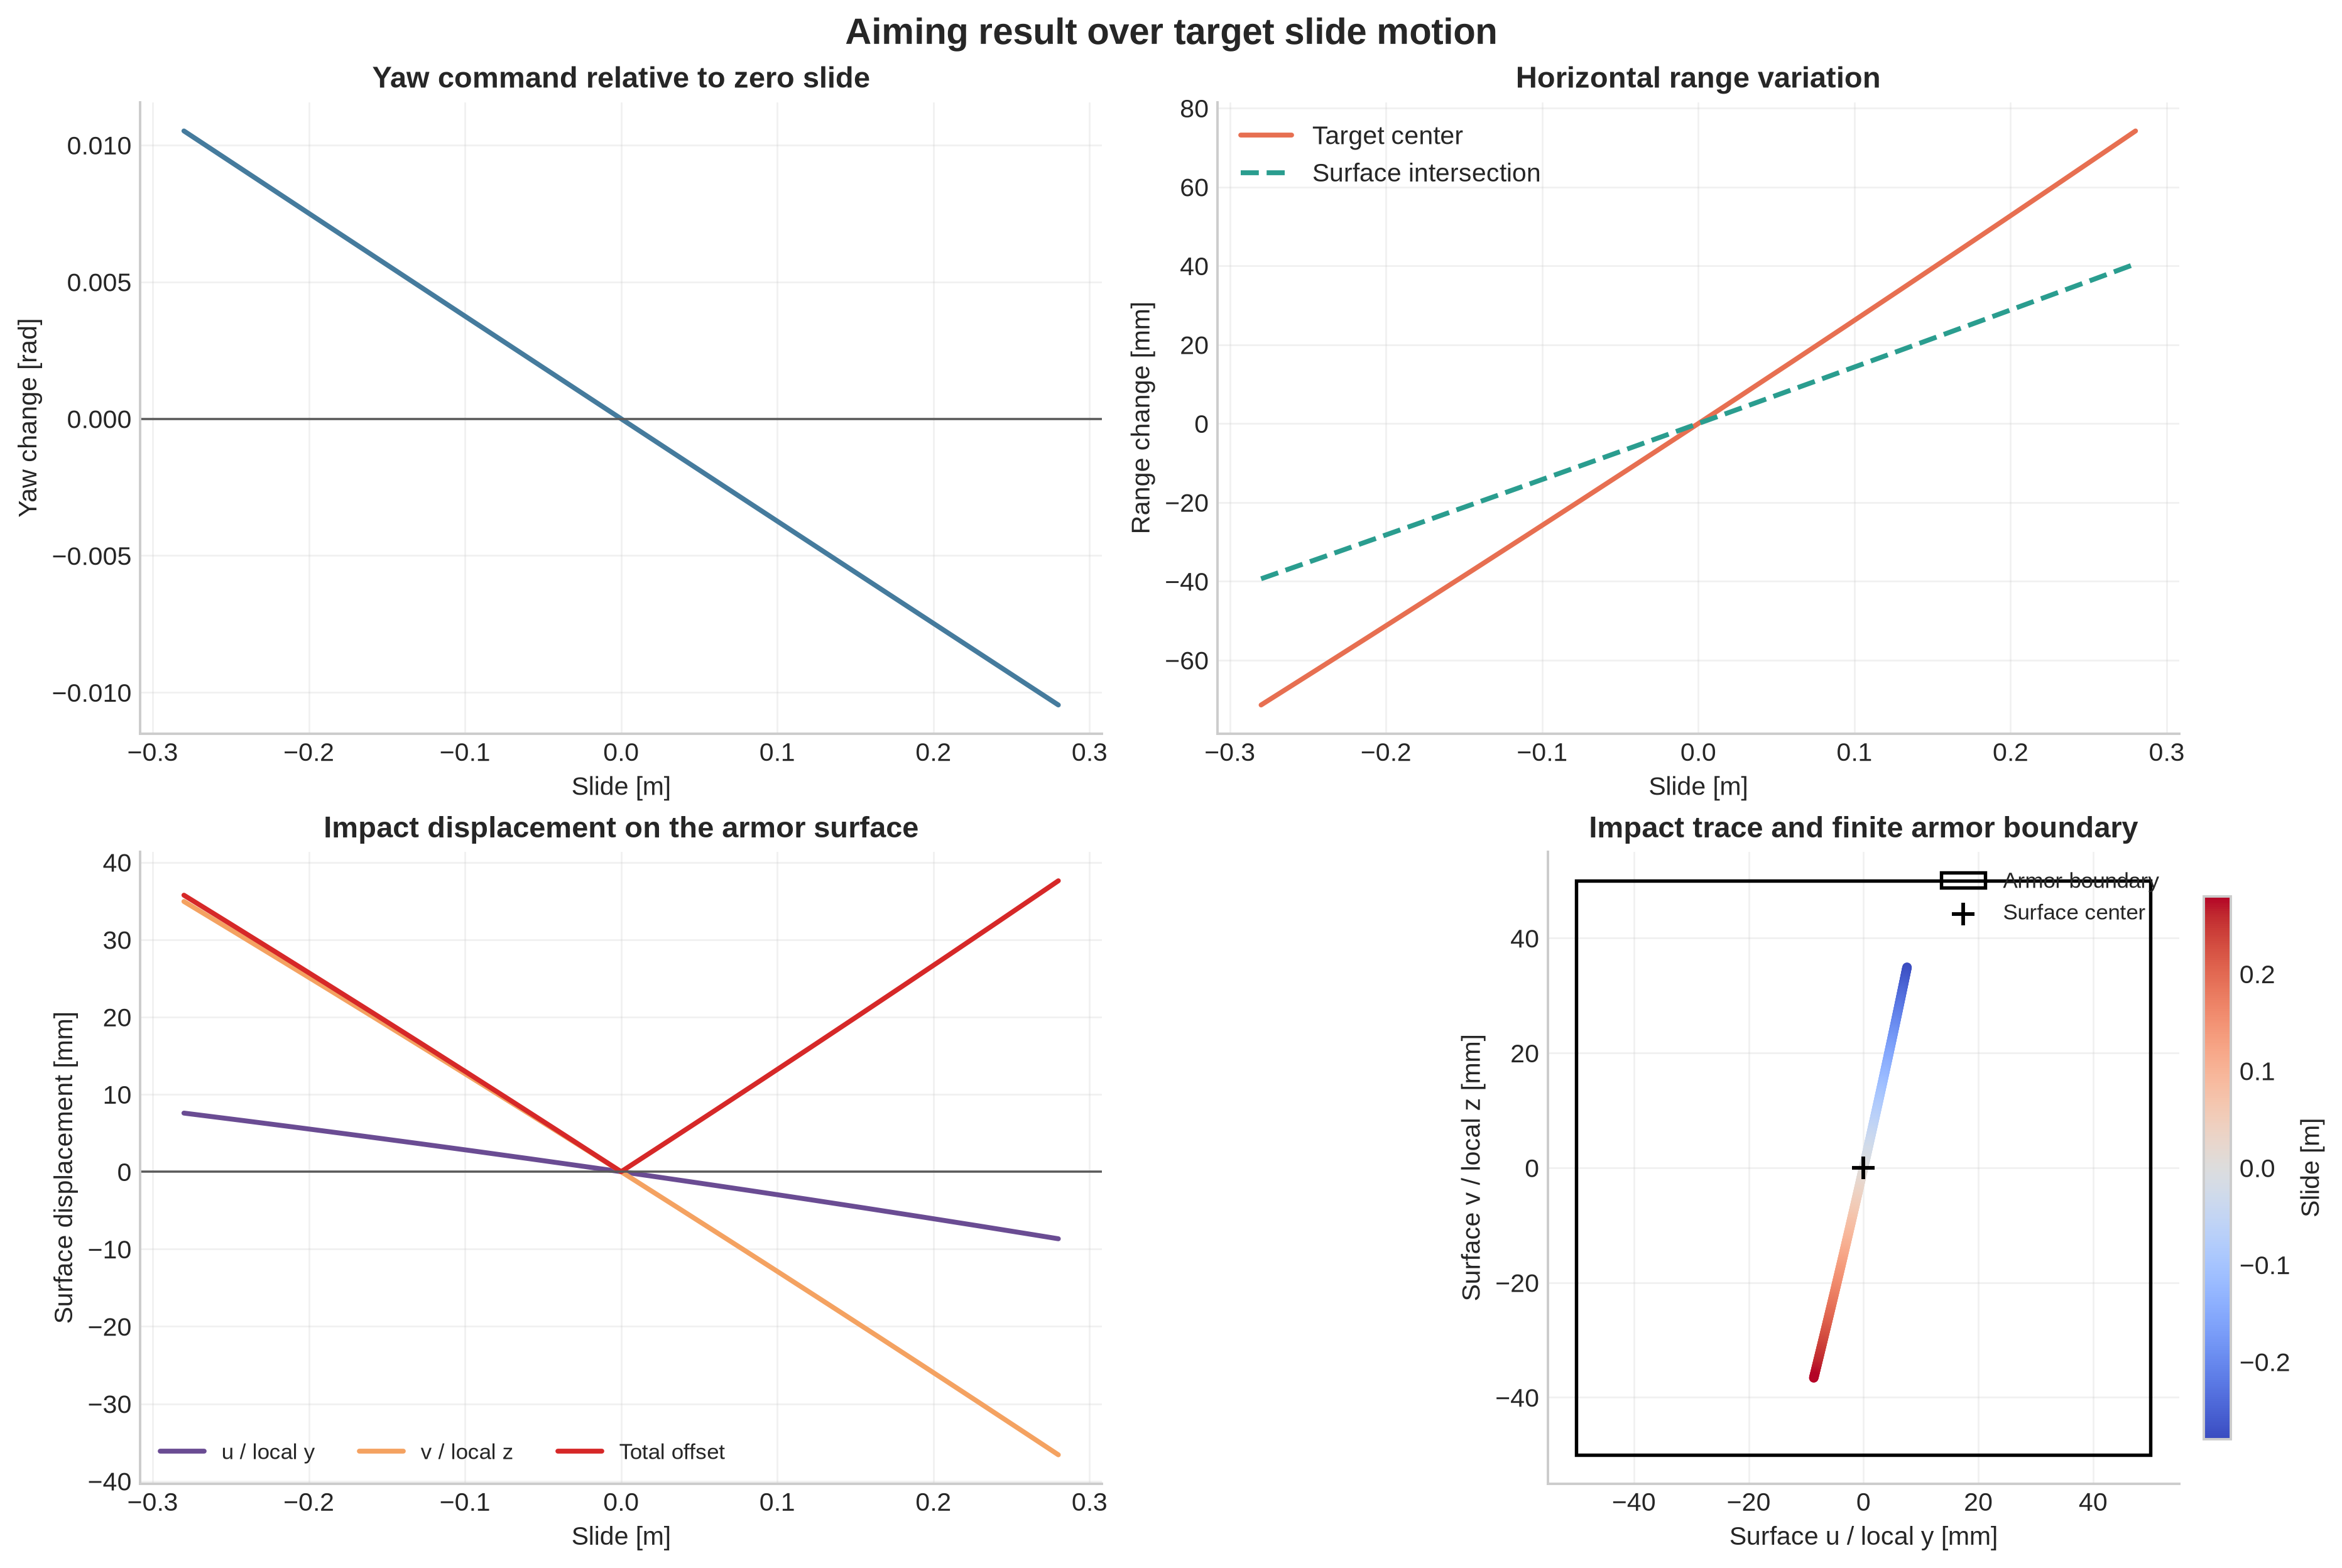

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13.2, 8.8), constrained_layout=True)

axes[0, 0].plot(results['slide_m'], results['yaw_delta_rad'], color=COLORS['yaw'])
axes[0, 0].axhline(0.0, color='0.35', linewidth=0.9)
axes[0, 0].set(xlabel='Slide [m]', ylabel='Yaw change [rad]', title='Yaw command relative to zero slide')

range_delta = results['centerline_target_range_m'] - range0
intersection_delta = results['trajectory_horizontal_range_m'] - baseline_range
axes[0, 1].plot(results['slide_m'], range_delta * 1e3, color=COLORS['armor'], label='Target center')
axes[0, 1].plot(results['slide_m'], intersection_delta * 1e3, color=COLORS['green'], linestyle='--', label='Surface intersection')
axes[0, 1].set(xlabel='Slide [m]', ylabel='Range change [mm]', title='Horizontal range variation')
axes[0, 1].legend()

axes[1, 0].plot(results['slide_m'], results['surface_u_m'] * 1e3, color=COLORS['u'], label='u / local y')
axes[1, 0].plot(results['slide_m'], results['surface_v_m'] * 1e3, color=COLORS['v'], label='v / local z')
axes[1, 0].plot(results['slide_m'], results['surface_offset_m'] * 1e3, color=COLORS['offset'], label='Total offset')
axes[1, 0].axhline(0.0, color='0.35', linewidth=0.9)
axes[1, 0].set(xlabel='Slide [m]', ylabel='Surface displacement [mm]', title='Impact displacement on the armor surface')
axes[1, 0].legend(ncols=3, fontsize=9)

surface = geometry.armor_surface(0.0)
trace = axes[1, 1].scatter(
    results['surface_u_m'] * 1e3,
    results['surface_v_m'] * 1e3,
    c=results['slide_m'],
    s=15,
    cmap='coolwarm',
    edgecolors='none',
    rasterized=True,
)
half_u, half_v = surface.size_u * 500, surface.size_v * 500
axes[1, 1].add_patch(plt.Rectangle((-half_u, -half_v), 2 * half_u, 2 * half_v, fill=False, color='black', linewidth=1.4, label='Armor boundary'))
axes[1, 1].scatter([0], [0], marker='+', s=90, linewidth=1.5, color='black', label='Surface center')
axes[1, 1].set(xlabel='Surface u / local y [mm]', ylabel='Surface v / local z [mm]', title='Impact trace and finite armor boundary', aspect='equal')
axes[1, 1].legend(loc='best', fontsize=9)
colorbar = fig.colorbar(trace, ax=axes[1, 1], shrink=0.86, pad=0.02)
colorbar.set_label('Slide [m]')

fig.suptitle('Aiming result over target slide motion', fontsize=15, fontweight='bold')
finish_figure(fig, 'target_slide_aiming')


## 3. Fixed-target yaw-error sensitivity

这一节固定滑轨零位、装甲板位姿、发射仰角和轨迹曲率；离轨点随镖架 yaw 按 URDF 运动。以准确命中板面中心的 q0 为基准，仅注入 yaw_error_rad，直接计算 yaw 偏差在装甲板上的 u/v 位移、剩余边界裕量和越界范围。

这与上一节不同：上一节研究目标随滑轨移动后的几何瞄准结果；本节研究固定目标下视觉或控制 yaw 误差的影响。

In [13]:
YAW_ERROR_LIMIT_RAD = 0.0025
YAW_ERROR_SAMPLES = 501
yaw_errors = np.linspace(-YAW_ERROR_LIMIT_RAD, YAW_ERROR_LIMIT_RAD, YAW_ERROR_SAMPLES)
error_surface = geometry.armor_surface(0.0)
error_half_u = error_surface.size_u / 2
error_half_v = error_surface.size_v / 2

yaw_error_rows = []
for yaw_error in yaw_errors:
    horizontal_range, hit, local, inside = intersect_armor_surface(0.0, q0 + float(yaw_error))
    boundary_margin = min(error_half_u - abs(local[0]), error_half_v - abs(local[1]))
    yaw_error_rows.append({
        'yaw_error_rad': yaw_error,
        'commanded_yaw_rad': q0 + yaw_error,
        'trajectory_horizontal_range_m': horizontal_range,
        'surface_u_m': local[0],
        'surface_v_m': local[1],
        'surface_normal_error_m': local[2],
        'surface_offset_m': np.hypot(local[0], local[1]),
        'boundary_margin_m': boundary_margin,
        'inside_armor': inside,
    })

yaw_error_results = pd.DataFrame(yaw_error_rows)
display(yaw_error_results.iloc[[0, len(yaw_error_results) // 4, len(yaw_error_results) // 2, 3 * len(yaw_error_results) // 4, -1]].round(8))

assert np.all((q0 + yaw_errors >= geometry.joint_limits(YAW_JOINT)[0]) &
              (q0 + yaw_errors <= geometry.joint_limits(YAW_JOINT)[1])), 'Yaw sweep exceeds mechanical limits'


,yaw_error_rad,commanded_yaw_rad,trajectory_horizontal_range_m,surface_u_m,surface_v_m,surface_normal_error_m,surface_offset_m,boundary_margin_m,inside_armor
0,-0.00250,-0.26561,25.579804,0.064822,-0.008580,-0.0,0.065388,-0.014822,False
125,-0.00125,-0.26436,25.575016,0.032408,-0.004277,-0.0,0.032689,0.017592,True
250,0.00000,-0.26311,25.570246,-0.000000,0.000000,0.0,0.000000,0.050000,True
375,0.00125,-0.26186,25.565495,-0.032402,0.004250,-0.0,0.032679,0.017598,True
500,0.00250,-0.26061,25.560764,-0.064797,0.008474,-0.0,0.065349,-0.014797,False


In [14]:
yaw_zero_index = int(np.abs(yaw_error_results['yaw_error_rad']).argmin())
du_dyaw = np.gradient(yaw_error_results['surface_u_m'] * 1e3, yaw_error_results['yaw_error_rad'])
dv_dyaw = np.gradient(yaw_error_results['surface_v_m'] * 1e3, yaw_error_results['yaw_error_rad'])
inside_errors = yaw_error_results.loc[yaw_error_results['inside_armor'], 'yaw_error_rad']

def displacement_at_yaw_error(yaw_error_rad):
    _, _, local, inside = intersect_armor_surface(0.0, q0 + yaw_error_rad)
    return local, inside


reference_error_rad = 4e-4
reference_local, reference_inside = displacement_at_yaw_error(reference_error_rad)
yaw_error_summary = pd.Series({
    'local_du_dyaw_mm_per_rad': du_dyaw[yaw_zero_index],
    'local_dv_dyaw_mm_per_rad': dv_dyaw[yaw_zero_index],
    'negative_inside_limit_rad_sampled': inside_errors.min(),
    'positive_inside_limit_rad_sampled': inside_errors.max(),
    'offset_at_4e-4_rad_mm': np.hypot(reference_local[0], reference_local[1]) * 1e3,
    'inside_at_4e-4_rad': reference_inside,
    'maximum_surface_normal_residual_um': yaw_error_results['surface_normal_error_m'].abs().max() * 1e6,
})
display(yaw_error_summary.round(6))


local_du_dyaw_mm_per_rad             -25923.918561
local_dv_dyaw_mm_per_rad               3410.802705
negative_inside_limit_rad_sampled         -0.00192
positive_inside_limit_rad_sampled          0.00192
offset_at_4e-4_rad_mm                    10.458437
inside_at_4e-4_rad                               1
maximum_surface_normal_residual_um             0.0
dtype: object

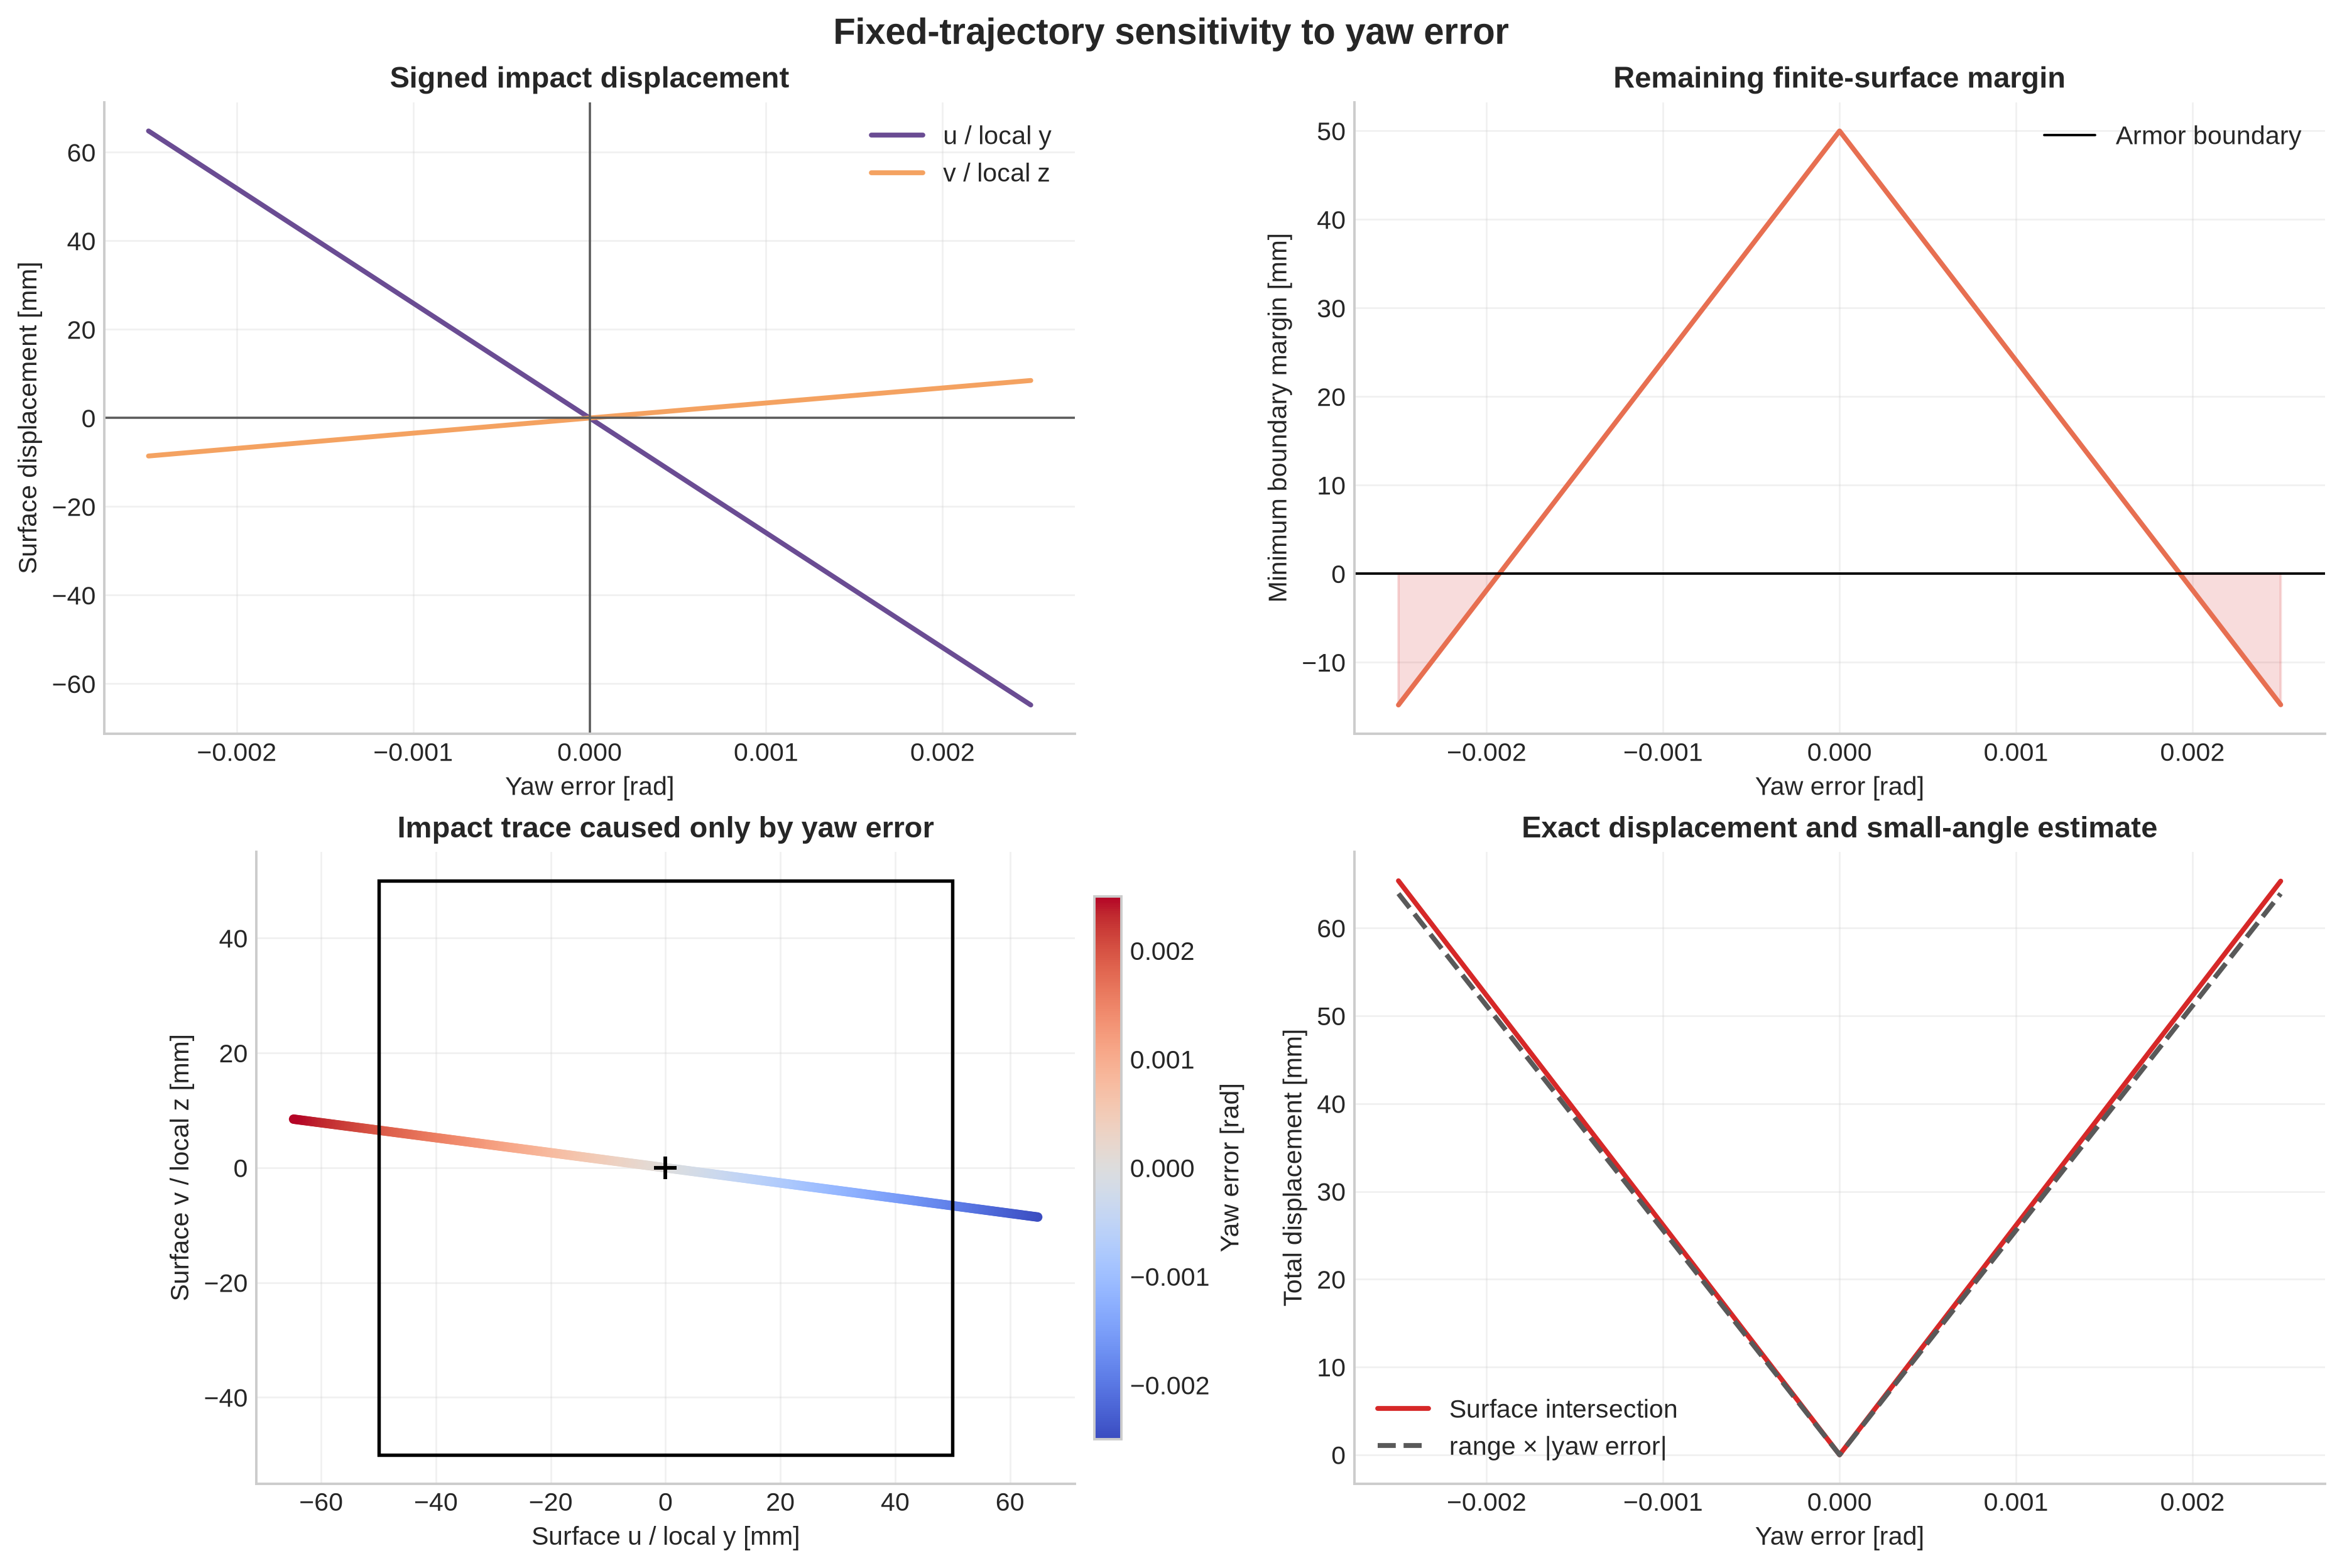

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13.2, 8.8), constrained_layout=True)

axes[0, 0].plot(yaw_error_results['yaw_error_rad'], yaw_error_results['surface_u_m'] * 1e3, color=COLORS['u'], label='u / local y')
axes[0, 0].plot(yaw_error_results['yaw_error_rad'], yaw_error_results['surface_v_m'] * 1e3, color=COLORS['v'], label='v / local z')
axes[0, 0].axvline(0.0, color='0.35', linewidth=0.9)
axes[0, 0].axhline(0.0, color='0.35', linewidth=0.9)
axes[0, 0].set(xlabel='Yaw error [rad]', ylabel='Surface displacement [mm]', title='Signed impact displacement')
axes[0, 0].legend()

axes[0, 1].plot(yaw_error_results['yaw_error_rad'], yaw_error_results['boundary_margin_m'] * 1e3, color=COLORS['armor'])
axes[0, 1].axhline(0.0, color='black', linewidth=1.0, label='Armor boundary')
axes[0, 1].fill_between(yaw_error_results['yaw_error_rad'], yaw_error_results['boundary_margin_m'] * 1e3, 0.0, where=yaw_error_results['boundary_margin_m'] < 0.0, color='#d62828', alpha=0.16)
axes[0, 1].set(xlabel='Yaw error [rad]', ylabel='Minimum boundary margin [mm]', title='Remaining finite-surface margin')
axes[0, 1].legend()

error_trace = axes[1, 0].scatter(
    yaw_error_results['surface_u_m'] * 1e3,
    yaw_error_results['surface_v_m'] * 1e3,
    c=yaw_error_results['yaw_error_rad'],
    s=15,
    cmap='coolwarm',
    edgecolors='none',
    rasterized=True,
)
axes[1, 0].add_patch(plt.Rectangle((-error_half_u * 1e3, -error_half_v * 1e3), error_surface.size_u * 1e3, error_surface.size_v * 1e3, fill=False, color='black', linewidth=1.4))
axes[1, 0].scatter([0], [0], marker='+', s=90, linewidth=1.5, color='black')
axes[1, 0].set(xlabel='Surface u / local y [mm]', ylabel='Surface v / local z [mm]', title='Impact trace caused only by yaw error', aspect='equal')
error_colorbar = fig.colorbar(error_trace, ax=axes[1, 0], shrink=0.86, pad=0.02)
error_colorbar.set_label('Yaw error [rad]')

linear_offset_mm = range0 * np.abs(yaw_error_results['yaw_error_rad']) * 1e3
axes[1, 1].plot(yaw_error_results['yaw_error_rad'], yaw_error_results['surface_offset_m'] * 1e3, color=COLORS['offset'], label='Surface intersection')
axes[1, 1].plot(yaw_error_results['yaw_error_rad'], linear_offset_mm, color='0.35', linestyle='--', label='range × |yaw error|')
axes[1, 1].set(xlabel='Yaw error [rad]', ylabel='Total displacement [mm]', title='Exact displacement and small-angle estimate')
axes[1, 1].legend()

fig.suptitle('Fixed-trajectory sensitivity to yaw error', fontsize=15, fontweight='bold')
finish_figure(fig, 'yaw_error_armor_displacement')


## 4. Vision angular and distance precision

使用当前相机焦距和 URDF 双目基线建立一阶精度预算。假设左右图像的目标中心误差独立且标准差相同：单目角度标准差约为 sigma_px / fx，双目平均方向约为 sigma_px / (sqrt(2) fx)；双目距离满足 Z = fx B / disparity。

这些数值是理想随机误差下限，不包含外参偏差、畸变残差、同步误差和结构振动。距离误差如何进一步变成落点误差还取决于下位机的距离到力度控制模型；当前仓库没有该模型，因此这里不虚构这一映射。
深度 Z 使用零位几何瞄准 yaw 下的绿灯相机光轴深度。当前左右 optical frame 存在图像轴方向差异，下面的 fx·B/Z 按完成校正后的理想双目解释，并非原始图像的水平像素差。角度噪声映射到镖架 yaw 的公式仍为近轴近似，未做完整姿态雅可比传播。目标中心是否位于两张图像内会单独报告，尚未分析目标轮廓和遮挡。


In [16]:
sensor_config_path = REPO_ROOT / 'third_party/dart_description/config/sensor_fov.yaml'
sensor_parameters = yaml.safe_load(sensor_config_path.read_text())['sensor_fov_visualizer']['ros__parameters']
focal_length_px = float(sensor_parameters['left_camera.fx'])

left_camera = geometry.position('left_camera_optical_frame', reference='stereo_camera_center_link')
right_camera = geometry.position('right_camera_optical_frame', reference='stereo_camera_center_link')
stereo_baseline_m = float(np.linalg.norm(left_camera - right_camera))
# Z is optical depth of the measured green feature, not launcher horizontal range.
camera_checks = []
for camera in ('left_camera', 'right_camera'):
    p = geometry.position('green_light_link', slide=0.0, launcher_yaw=q0,
                          reference=f'{camera}_optical_frame')
    fx, fy, cx, cy = [float(sensor_parameters[f'{camera}.{k}']) for k in ('fx','fy','cx','cy')]
    assert p[2] > 0, 'Target is behind a camera'
    u, v = fx * p[0] / p[2] + cx, fy * p[1] / p[2] + cy
    camera_checks.append({'camera': camera, 'depth_m': p[2], 'u_px': u, 'v_px': v,
                          'center_in_image': bool(0 <= u < sensor_parameters[f'{camera}.width'] and
                                                  0 <= v < sensor_parameters[f'{camera}.height'])})
camera_checks = pd.DataFrame(camera_checks)
display(camera_checks)
precision_range_m = float(camera_checks['depth_m'].mean())
print('Budget assumes an ideal rectified stereo pair with these focal lengths and baseline.')
if not camera_checks['center_in_image'].all():
    print('Current model does not place the green center inside both images; the following is a hypothetical precision budget, not current observability.')
nominal_disparity_px = focal_length_px * stereo_baseline_m / precision_range_m

center_sigma_px = np.array([0.1, 0.25, 0.5, 1.0])
single_camera_yaw_sigma_rad = center_sigma_px / focal_length_px
stereo_yaw_sigma_rad = single_camera_yaw_sigma_rad / np.sqrt(2)
disparity_sigma_px = np.sqrt(2) * center_sigma_px
distance_sigma_m = (
    precision_range_m**2 / (focal_length_px * stereo_baseline_m) * disparity_sigma_px
)
yaw_to_surface_gain_mm_per_rad = float(np.hypot(du_dyaw[yaw_zero_index], dv_dyaw[yaw_zero_index]))
surface_sigma_mm = yaw_to_surface_gain_mm_per_rad * stereo_yaw_sigma_rad

vision_precision = pd.DataFrame({
    'center_sigma_px_each_camera': center_sigma_px,
    'single_camera_yaw_sigma_rad': single_camera_yaw_sigma_rad,
    'ideal_stereo_yaw_sigma_rad': stereo_yaw_sigma_rad,
    'ideal_surface_sigma_mm': surface_sigma_mm,
    'disparity_sigma_px': disparity_sigma_px,
    'ideal_distance_sigma_m': distance_sigma_m,
})
display(pd.Series({
    'focal_length_px': focal_length_px,
    'stereo_baseline_m': stereo_baseline_m,
    'evaluation_optical_depth_m': precision_range_m,
    'nominal_disparity_px': nominal_disparity_px,
    'yaw_to_surface_gain_mm_per_rad': yaw_to_surface_gain_mm_per_rad,
}).round(6))
display(vision_precision)


,camera,depth_m,u_px,v_px,center_in_image
0,left_camera,25.405158,1015.594453,634.591646,True
1,right_camera,25.405158,423.405547,609.843207,True


Budget assumes an ideal rectified stereo pair with these focal lengths and baseline.


focal_length_px                   14492.753623
stereo_baseline_m                     0.290000
evaluation_optical_depth_m           25.405158
nominal_disparity_px                165.434854
yaw_to_surface_gain_mm_per_rad    26147.335020
dtype: float64

,center_sigma_px_each_camera,single_camera_yaw_sigma_rad,ideal_stereo_yaw_sigma_rad,ideal_surface_sigma_mm,disparity_sigma_px,ideal_distance_sigma_m
0,0.10,0.000007,0.000005,0.127574,0.141421,0.021718
1,0.25,0.000017,0.000012,0.318935,0.353553,0.054294
2,0.50,0.000034,0.000024,0.637869,0.707107,0.108588
3,1.00,0.000069,0.000049,1.275738,1.414214,0.217175


In [17]:
surface_error_budgets_mm = np.array([2.5, 5.0, 10.0, 20.0])
yaw_requirement = pd.DataFrame({
    'surface_error_budget_mm': surface_error_budgets_mm,
    'maximum_abs_yaw_error_rad': surface_error_budgets_mm / yaw_to_surface_gain_mm_per_rad,
    'maximum_yaw_sigma_for_95_percent_rad': surface_error_budgets_mm / (1.96 * yaw_to_surface_gain_mm_per_rad),
})
display(yaw_requirement)


,surface_error_budget_mm,maximum_abs_yaw_error_rad,maximum_yaw_sigma_for_95_percent_rad
0,2.5,0.000096,0.000049
1,5.0,0.000191,0.000098
2,10.0,0.000382,0.000195
3,20.0,0.000765,0.000390


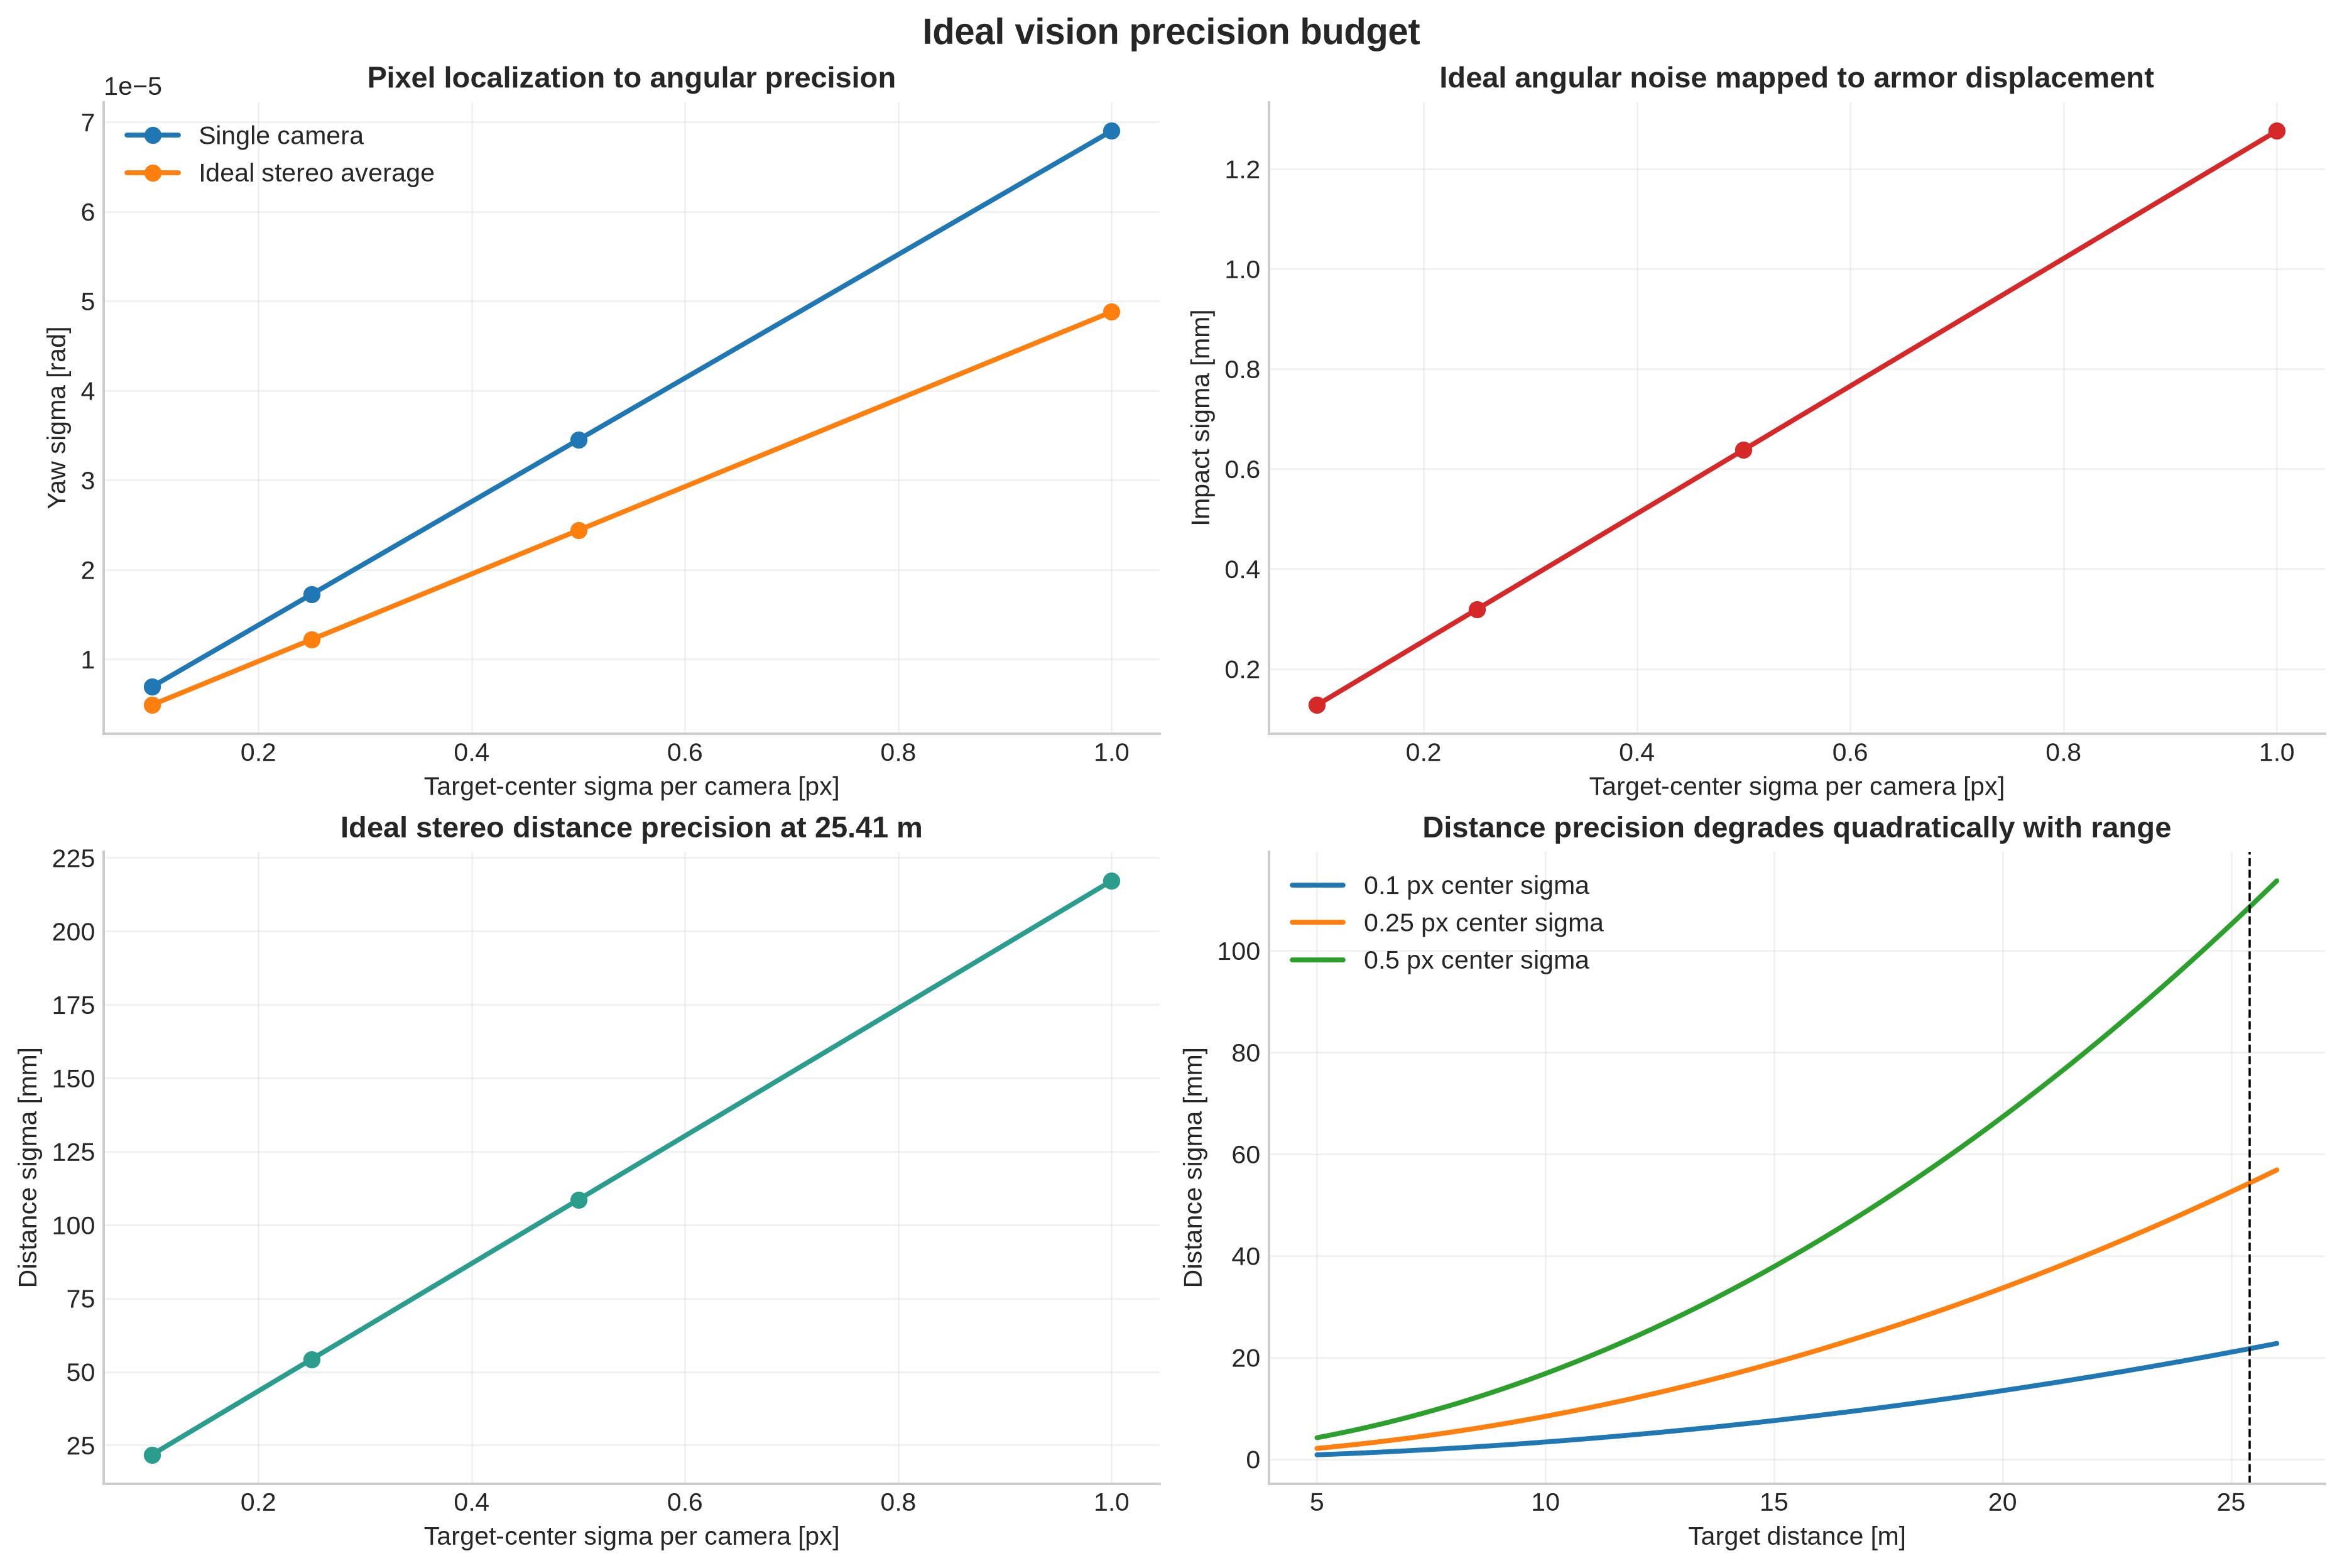

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13.2, 8.8), constrained_layout=True)

axes[0, 0].plot(center_sigma_px, single_camera_yaw_sigma_rad, marker='o', label='Single camera')
axes[0, 0].plot(center_sigma_px, stereo_yaw_sigma_rad, marker='o', label='Ideal stereo average')
axes[0, 0].set(xlabel='Target-center sigma per camera [px]', ylabel='Yaw sigma [rad]', title='Pixel localization to angular precision')
axes[0, 0].legend()

axes[0, 1].plot(center_sigma_px, surface_sigma_mm, marker='o', color=COLORS['offset'])
axes[0, 1].set(xlabel='Target-center sigma per camera [px]', ylabel='Impact sigma [mm]', title='Ideal angular noise mapped to armor displacement')

axes[1, 0].plot(center_sigma_px, distance_sigma_m * 1e3, marker='o', color=COLORS['green'])
axes[1, 0].set(xlabel='Target-center sigma per camera [px]', ylabel='Distance sigma [mm]', title=f'Ideal stereo distance precision at {precision_range_m:.2f} m')

distance_grid_m = np.linspace(5.0, float(sensor_parameters['left_camera.far_m']), 250)
for sigma_px in (0.1, 0.25, 0.5):
    sigma_distance_grid_m = distance_grid_m**2 / (focal_length_px * stereo_baseline_m) * np.sqrt(2) * sigma_px
    axes[1, 1].plot(distance_grid_m, sigma_distance_grid_m * 1e3, label=f'{sigma_px:g} px center sigma')
axes[1, 1].axvline(precision_range_m, color='black', linestyle='--', linewidth=0.9)
axes[1, 1].set(xlabel='Target distance [m]', ylabel='Distance sigma [mm]', title='Distance precision degrades quadratically with range')
axes[1, 1].legend()

fig.suptitle('Ideal vision precision budget', fontsize=15, fontweight='bold')
finish_figure(fig, 'vision_angle_distance_precision')


## Summary

In [19]:
inside_statement = (
    '全部采样点都落在有限装甲板内'
    if bool(results['inside_armor'].all())
    else f"仅 {results['inside_armor'].mean() * 100:.1f}% 的采样点落在有限装甲板内"
)
constant_statement = (
    '可以使用该常量'
    if constant_yaw_is_acceptable
    else '不能在当前误差预算下使用该常量'
)
reference_precision = vision_precision.iloc[1]

display(Markdown(f'''\
### 当前 URDF 下的几何模型结果（{TEAM} 方，基地）

1. 绿灯到装甲板的候选常量 yaw 补偿为 **{constant_yaw_offset_rad:.8f} rad**，全行程最大等效水平横向误差为 **{max_constant_lateral_error_m * 1e3:.3f} mm**；在 **{CONSTANT_YAW_LATERAL_ERROR_BUDGET_M * 1e3:.1f} mm** 预算下，**{constant_statement}**。
2. 目标随滑轨移动时，完整行程需要 **{np.ptp(results['yaw_rad']):.6f} rad** 的 yaw 调整，零位附近灵敏度为 **{yaw_gradient[zero_index]:.6f} rad/m**；固定基准轨迹下最坏撞击偏移为 **{worst['surface_offset_m'] * 1e3:.3f} mm**，{inside_statement}。
3. 固定装甲板与基准曲线时，du/dyaw = **{du_dyaw[yaw_zero_index]:.1f} mm/rad**、dv/dyaw = **{dv_dyaw[yaw_zero_index]:.1f} mm/rad**；**4e-4 rad** yaw 误差造成 **{np.hypot(reference_local[0], reference_local[1]) * 1e3:.3f} mm** 位移，采样估计的板内 yaw 范围约为 **[{inside_errors.min():.6f}, {inside_errors.max():.6f}] rad**。
4. 在每台相机中心定位 sigma = **{reference_precision['center_sigma_px_each_camera']:.2f} px** 的理想独立噪声假设下，近轴近似的双目 yaw sigma 约 **{reference_precision['ideal_stereo_yaw_sigma_rad']:.3e} rad**、板面位移 sigma 约 **{reference_precision['ideal_surface_sigma_mm']:.3f} mm**、距离 sigma 约 **{reference_precision['ideal_distance_sigma_m'] * 1e3:.1f} mm**。
- 数值质量检查：最大水平中心线残差 **{results['centerline_error_m'].abs().max() * 1e6:.3e} um**，最大板面法向残差 **{results['surface_normal_error_m'].abs().max() * 1e6:.3e} um**。

### 适用边界

这些结果不能替代完整弹道和标定误差模型。角度/距离精度表仅表示像素随机误差的一阶理论下限；实际验收还必须包含内外参偏差、同步误差和结构振动。仓库目前没有距离到发射力度的控制模型，因此不能仅凭视觉距离 sigma 推导最终落点误差。
'''))

assert np.isfinite(results.select_dtypes(include=[np.number]).to_numpy()).all()
assert results['centerline_error_m'].abs().max() < 1e-8
assert results['surface_normal_error_m'].abs().max() < 1e-7
assert baseline_inside and np.linalg.norm(baseline_local) < 1e-7
print('Numerical checks passed; visibility is reported separately above.')


### 当前 URDF 下的几何模型结果（red 方，基地）

1. 绿灯到装甲板的候选常量 yaw 补偿为 **0.00084453 rad**，全行程最大等效水平横向误差为 **0.872 mm**；在 **5.0 mm** 预算下，**可以使用该常量**。
2. 目标随滑轨移动时，完整行程需要 **0.020975 rad** 的 yaw 调整，零位附近灵敏度为 **-0.037456 rad/m**；固定基准轨迹下最坏撞击偏移为 **37.613 mm**，全部采样点都落在有限装甲板内。
3. 固定装甲板与基准曲线时，du/dyaw = **-25923.9 mm/rad**、dv/dyaw = **3410.8 mm/rad**；**4e-4 rad** yaw 误差造成 **10.458 mm** 位移，采样估计的板内 yaw 范围约为 **[-0.001920, 0.001920] rad**。
4. 在每台相机中心定位 sigma = **0.25 px** 的理想独立噪声假设下，近轴近似的双目 yaw sigma 约 **1.220e-05 rad**、板面位移 sigma 约 **0.319 mm**、距离 sigma 约 **54.3 mm**。
- 数值质量检查：最大水平中心线残差 **3.553e-09 um**，最大板面法向残差 **9.127e-09 um**。

### 适用边界

这些结果不能替代完整弹道和标定误差模型。角度/距离精度表仅表示像素随机误差的一阶理论下限；实际验收还必须包含内外参偏差、同步误差和结构振动。仓库目前没有距离到发射力度的控制模型，因此不能仅凭视觉距离 sigma 推导最终落点误差。


Numerical checks passed; visibility is reported separately above.
